# 5. IPM, NBI y educación: ¿hay un "efecto Chocó"?

Tres preguntas:

1. ¿El IPM y las Necesidades Básicas Insatisfechas (NBI) cuentan la misma historia en el Chocó?
2. ¿Qué tan ligados están la pobreza del hogar y los resultados de Saber 11 de los colegios del municipio?
3. Si se compara al Chocó con municipios **igual de rurales y del mismo tamaño**, ¿sigue siendo más pobre?
   Es decir: ¿la ruralidad lo explica todo, o queda algo propio del Chocó?

In [1]:
# Preparación: ubica la carpeta del repo y carga el paquete del estudio
import sys
from pathlib import Path

RAIZ = Path.cwd().resolve()
for _ in range(5):
    if (RAIZ / "src" / "pobreza").exists():
        break
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pobreza import datos, ipm
from pobreza.config import ETIQUETAS, IPM_INDICADORES, DIMENSIONES, PACIFICO, REPORTES
from pobreza.graficos import CHOCO, RESTO, ACENTO, NEUTRO, DIMENSION_COLORES, estilo, guardar, fuente

estilo()
pd.set_option("display.float_format", lambda x: f"{x:,.1f}")
pd.set_option("display.max_columns", 40)
import statsmodels.formula.api as smf

In [2]:
base = datos.base_municipal()
choco = base[base.es_choco]

## 5.1 IPM contra NBI

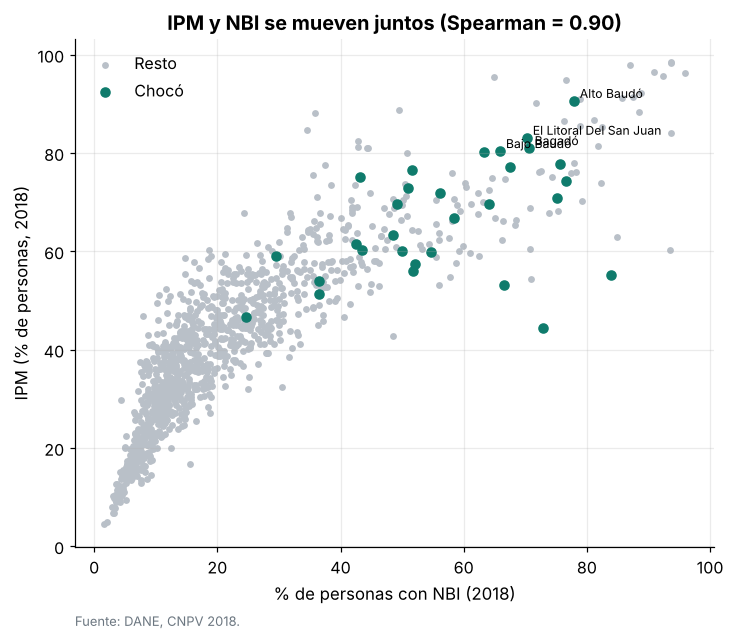

El IPM es más alto que el NBI en casi todos los municipios porque mide más cosas (salud, empleo,
logro educativo de los adultos), no solo vivienda, servicios y dependencia.


In [3]:
if "nbi" in base:
    r = base[["ipm", "nbi"]].corr(method="spearman").iloc[0, 1]
    fig, ax = plt.subplots(figsize=(7.5, 6))
    ax.scatter(base.loc[~base.es_choco, "nbi"], base.loc[~base.es_choco, "ipm"], s=12, color=RESTO, label="Resto")
    ax.scatter(choco["nbi"], choco["ipm"], s=35, color=CHOCO, label="Chocó")
    for _, f in choco.nlargest(4, "ipm").iterrows():
        ax.annotate(f["municipio"], (f["nbi"], f["ipm"]), fontsize=8, xytext=(4, 2), textcoords="offset points")
    ax.set(xlabel="% de personas con NBI (2018)", ylabel="IPM (% de personas, 2018)",
           title=f"IPM y NBI se mueven juntos (Spearman = {r:.2f})")
    ax.legend()
    fuente(ax, "DANE, CNPV 2018.")
    guardar(fig, "05_ipm_vs_nbi")
    plt.show()
    print("El IPM es más alto que el NBI en casi todos los municipios porque mide más cosas (salud, empleo,")
    print("logro educativo de los adultos), no solo vivienda, servicios y dependencia.")
else:
    print("No hay NBI disponible.")

## 5.2 Pobreza y resultados de Saber 11

Puntaje global promedio de los estudiantes de colegios ubicados en cada municipio, en los años completos
más cercanos al censo de 2018 (la base de datos.gov.co casi no trae 2018).

Saber 11, años usados: 2017 y 2019; municipios con dato: 1113


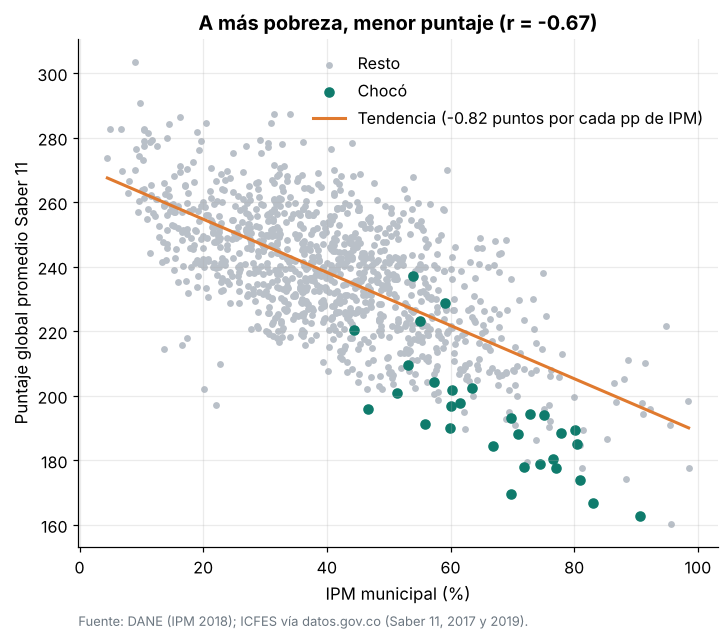

Residuo promedio del Chocó: -22.8 puntos (negativo = sacan menos de lo que predice su nivel de pobreza)


In [4]:
if "punt_global" in base and base["punt_global"].notna().sum() > 30:
    d = base.dropna(subset=["punt_global", "ipm"])
    anios_s11 = d["anios_saber11"].iloc[0] if "anios_saber11" in d else "2018"
    print(f"Saber 11, años usados: {anios_s11}; municipios con dato: {len(d)}")
    r = d[["ipm", "punt_global"]].corr().iloc[0, 1]
    fig, ax = plt.subplots(figsize=(7.5, 6))
    ax.scatter(d.loc[~d.es_choco, "ipm"], d.loc[~d.es_choco, "punt_global"], s=12, color=RESTO, label="Resto")
    ax.scatter(d.loc[d.es_choco, "ipm"], d.loc[d.es_choco, "punt_global"], s=35, color=CHOCO, label="Chocó")
    m, b = np.polyfit(d["ipm"], d["punt_global"], 1)
    xs = np.linspace(d["ipm"].min(), d["ipm"].max(), 50)
    ax.plot(xs, m * xs + b, color=ACENTO, lw=2, label=f"Tendencia ({m:.2f} puntos por cada pp de IPM)")
    ax.set(xlabel="IPM municipal (%)", ylabel="Puntaje global promedio Saber 11",
           title=f"A más pobreza, menor puntaje (r = {r:.2f})")
    ax.legend()
    fuente(ax, f"DANE (IPM 2018); ICFES vía datos.gov.co (Saber 11, {anios_s11}).")
    guardar(fig, "05_ipm_vs_saber11")
    plt.show()
    d = d.assign(residuo=d["punt_global"] - (m * d["ipm"] + b))
    print(f"Residuo promedio del Chocó: {d.loc[d.es_choco, 'residuo'].mean():+.1f} puntos "
          "(negativo = sacan menos de lo que predice su nivel de pobreza)")
else:
    print("No hay datos de Saber 11 suficientes (la descarga es opcional).")

## 5.3 ¿Queda un "efecto Chocó" después de tener en cuenta la ruralidad y el tamaño?

Regresión lineal por mínimos cuadrados a nivel municipal:

$$\text{IPM}_m = \beta_0 + \beta_1\,\text{Chocó}_m + \beta_2\,\%\text{rural}_m + \beta_3\,\log(\text{población}_m) + \varepsilon_m$$

$\beta_1$ dice cuántos puntos más (o menos) de IPM tiene un municipio del Chocó **frente a uno del resto del
país con la misma ruralidad y el mismo tamaño**. Errores estándar robustos (HC3).

Esto no es causal: el "efecto Chocó" junta todo lo que no está en el modelo (aislamiento geográfico,
conflicto, capacidad institucional, discriminación histórica, inversión pública, etc.).

In [5]:
modelo = None
if {"pct_rural", "poblacion_total"} <= set(base.columns):
    d = base.dropna(subset=["ipm", "pct_rural", "poblacion_total"]).assign(
        choco=lambda x: x.es_choco.astype(int), log_pob=lambda x: np.log(x.poblacion_total))
    modelos = {
        "(1) Solo Chocó": smf.ols("ipm ~ choco", d).fit(cov_type="HC3"),
        "(2) + ruralidad": smf.ols("ipm ~ choco + pct_rural", d).fit(cov_type="HC3"),
        "(3) + tamaño": smf.ols("ipm ~ choco + pct_rural + log_pob", d).fit(cov_type="HC3"),
    }
    resumen = pd.DataFrame({n: {"Efecto Chocó (pp)": m.params["choco"], "Error estándar": m.bse["choco"],
                                "IC 95% inferior": m.conf_int().loc["choco", 0],
                                "IC 95% superior": m.conf_int().loc["choco", 1],
                                "R²": m.rsquared, "Municipios": int(m.nobs)} for n, m in modelos.items()}).T
    display(resumen.round(2))
    modelo = modelos["(3) + tamaño"]
    print(modelo.summary().tables[1])

,Efecto Chocó (pp),Error estándar,IC 95% inferior,IC 95% superior,R²,Municipios
(1) Solo Chocó,25.6,2.2,21.2,30.0,0.1,"1,122.0"
(2) + ruralidad,22.5,1.4,19.8,25.1,0.3,"1,122.0"
(3) + tamaño,22.5,1.4,19.8,25.2,0.3,"1,122.0"


                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     22.9775      5.316      4.322      0.000      12.558      33.397
choco         22.5162      1.370     16.438      0.000      19.832      25.201
pct_rural      0.3537      0.024     14.825      0.000       0.307       0.400
log_pob       -0.1805      0.464     -0.389      0.697      -1.089       0.728


## 5.4 Lo mismo, indicador por indicador

¿En qué privaciones el Chocó está peor que municipios igual de rurales y del mismo tamaño?

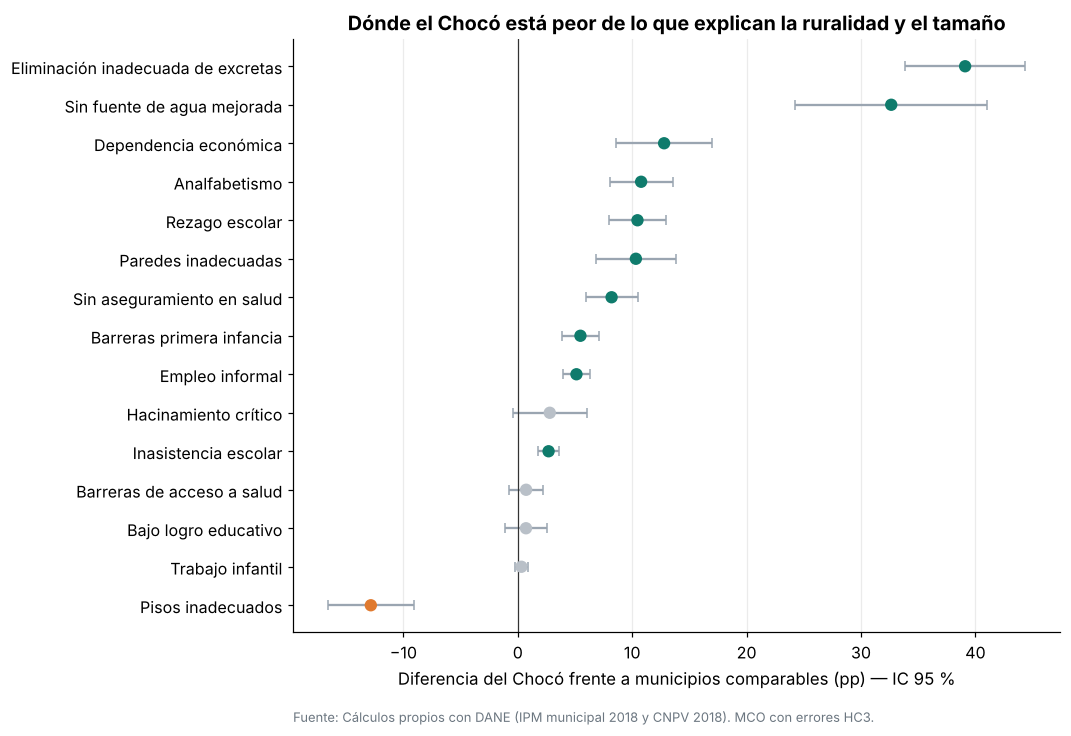

In [6]:
if modelo is not None:
    filas = []
    for i in ipm.indicadores_presentes(base):
        m = smf.ols(f"{i} ~ choco + pct_rural + log_pob", d).fit(cov_type="HC3")
        lo, hi = m.conf_int().loc["choco"]
        filas.append({"indicador": ETIQUETAS[i], "efecto": m.params["choco"], "lo": lo, "hi": hi})
    ef = pd.DataFrame(filas).sort_values("efecto")
    fig, ax = plt.subplots(figsize=(9, 7))
    colores = [CHOCO if lo > 0 else (ACENTO if hi < 0 else RESTO) for lo, hi in zip(ef.lo, ef.hi)]
    ax.errorbar(ef["efecto"], ef["indicador"], xerr=[ef["efecto"] - ef["lo"], ef["hi"] - ef["efecto"]],
                fmt="none", ecolor="#9aa5b1", capsize=3)
    ax.scatter(ef["efecto"], ef["indicador"], color=colores, s=50, zorder=3)
    ax.axvline(0, color="#333", lw=0.8)
    ax.set(xlabel="Diferencia del Chocó frente a municipios comparables (pp) — IC 95 %",
           title="Dónde el Chocó está peor de lo que explican la ruralidad y el tamaño")
    ax.grid(axis="y", visible=False)
    fuente(ax, "Cálculos propios con DANE (IPM municipal 2018 y CNPV 2018). MCO con errores HC3.")
    guardar(fig, "05_efecto_choco_indicadores")
    plt.show()
    ef.round(2).to_csv(REPORTES / "efecto_choco_por_indicador.csv", index=False)

## Para llevar

- IPM y NBI coinciden en el orden de los municipios, pero el IPM ve privaciones que el NBI no mide.
- Si el efecto Chocó sigue siendo grande y significativo después de controlar por ruralidad y tamaño, la
  pobreza del Chocó **no se explica solo por ser rural**: hay brechas propias del departamento que una
  política general para la ruralidad no cerraría por sí sola.